# 图 1–3：黑白方法示意图

修改集中参数区，选择“重新启动内核并全部运行”。所有绘图函数均在本 notebook 内。每幅图执行后会显示预览，并导出到 `paper/figures`。保存 notebook 后双击 `paper/build_pdf.cmd` 更新论文。

尺寸与坐标单位为毫米，文字中的 `\n` 控制换行。通过 `*_X`、`*_Y`、`*_BOX` 调整方块与间距，`FONT_SCALE` 统一控制文字大小。

In [1]:
# ===== 集中参数区：尺寸为毫米，字号为 point =====
FONT_SCALE = 1.0
FONT_FAMILY = ["Times New Roman", "SimSun"]  # 英文与数字 / 中文
FONT_BODY = 9
FONT_TITLE = 11
FONT_NOTE = 8.5
LINE_WIDTH = 0.9
ARROW_SIZE = 9
DPI_PREVIEW = 150
DPI_EXPORT = 300
# 纯黑白：所有方块不填充，关系类型以线型区分
EDGE_COLOR = "black"
TEXT_COLOR = "black"
BOX_FILL = False
LINESTYLE_FORWARD = "-"
LINESTYLE_GRADIENT = "--"

# 图1：左侧观测数据，右侧两条任务路径。坐标原点在左下角。
ROUTE_SIZE = (160, 65)
ROUTE_BOX = (29, 16)
ROUTE_X = [19, 61, 103, 145]
ROUTE_Y = [48, 16]
ROUTE_BRANCH_X = 39
ROUTE_LABELS = {
    "obs": "观测数据\n组分状态时间序列",
    "known": "已知拓扑\n动力学学习",
    "unknown": "未知拓扑\n动力学与结构共学",
    "self": "分离自身演化\n与邻居交互",
    "joint": "交替学习离散连接\n与动力学规律",
    "prediction": "状态预测\n参数反演",
    "reconstruction": "动力学预测\n潜在拓扑恢复",
}

# 图2：两行对照；调 COLUMN_X / ROW_CENTERS / CHANNEL_GAP 即可调整布局。
ARCH_SIZE = (160, 105)
ARCH_COLUMN_X = [12, 51, 98, 143]
ARCH_ROW_CENTERS = [77, 27]
ARCH_CHANNEL_GAP = 19
ARCH_INPUT_BOX = (18, 12)
ARCH_TRANSFORM_BOX = (34, 15)
ARCH_MERGE_BOX = (35, 19)
ARCH_READOUT_BOX = (26, 16)
ARCH_TITLE_OFFSET = 21
ARCH_NOTE_OFFSET = -24
ARCH_NOTES = [
    "自身项与邻居项分别变换后，在同一隐藏表示中相加。",
    "自身与邻居信息保持分离，由非线性读出层联合建模。",
]

# 图3：上下两阶段，左侧为共同输入，右侧为各阶段的优化目标。
JOINT_SIZE = (160, 98)
JOINT_X = [18, 62, 106, 147]
JOINT_Y = [66, 32]
JOINT_BOX = (31, 20)
JOINT_DATA_BOX = (31, 25)
JOINT_RETURN_Y = 9
JOINT_LABELS = {
    "data": "状态转移对\n"+r"$({\mathbf{X}}_t,{\mathbf{X}}_{t+1})$"+"\n分层采样",
    "hard": "固定硬图\n"+r"$\hat A_{ij}\in\{0,1\}$",
    "learner": "动力学学习器\n更新规律参数",
    "loss1": "状态预测\n交叉熵",
    "soft": "可微软图\n"+r"$\hat A_{\rm soft}$",
    "generator": "固定学习器\n更新拓扑生成器",
    "loss2": "交叉熵\n熵正则",
}


In [2]:
from pathlib import Path
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

def find_root():
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "paper" / "main.tex").is_file():
            return p
    raise FileNotFoundError("请从项目目录或 paper/notebooks 内启动 notebook。")

ROOT = find_root()
PAPER = ROOT / "paper"
FIG_DIR = PAPER / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
from matplotlib.patches import Rectangle, FancyArrowPatch
plt.rcParams.update({
    "font.family": FONT_FAMILY, "mathtext.fontset": "stix",
    "axes.unicode_minus": False, "pdf.fonttype": 42,
    "figure.dpi": DPI_PREVIEW, "savefig.dpi": DPI_EXPORT,
})
def canvas(size):
    fig, ax = plt.subplots(figsize=(size[0] / 25.4, size[1] / 25.4))
    fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01)
    ax.set(xlim=(0, size[0]+3), ylim=(0, size[1]))
    ax.axis("off")
    return fig, ax

def box(ax, center, dimensions, label):
    x, y = center
    w, h = dimensions
    ax.add_patch(Rectangle((x-w/2, y-h/2), w, h,
                          fill=BOX_FILL, facecolor="white", edgecolor=EDGE_COLOR,
                          linewidth=LINE_WIDTH))
    txt = ax.text(x, y, label, ha="center", va="center", color=TEXT_COLOR,
                  fontsize=FONT_BODY*FONT_SCALE, linespacing=1.4)
    return {"left": (x-w/2, y), "right": (x+w/2, y),
            "top": (x, y+h/2), "bottom": (x, y-h/2)}

def arrow(ax, start, end, dashed=False):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>",
                 mutation_scale=ARROW_SIZE, linewidth=LINE_WIDTH, color=EDGE_COLOR,
                 linestyle=LINESTYLE_GRADIENT if dashed else LINESTYLE_FORWARD,
                 shrinkA=1.2, shrinkB=1.2))

def elbow(ax, points, dashed=False):
    style = LINESTYLE_GRADIENT if dashed else LINESTYLE_FORWARD
    for start, end in zip(points[:-2], points[1:-1]):
        ax.plot([start[0],end[0]], [start[1],end[1]], color=EDGE_COLOR,
                lw=LINE_WIDTH, ls=style)
    arrow(ax, points[-2], points[-1], dashed)

def export(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", facecolor="white")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=DPI_EXPORT, facecolor="white")
    display(fig)
    plt.close(fig)
    print(f"已导出 {name}.pdf 和 {name}.png")

def research_pipeline():
    fig, ax = canvas(ROUTE_SIZE)
    # 首尾框略向内收，所有节点位置仍集中由 ROUTE_X 定义。
    xs = ROUTE_X
    dims = ROUTE_BOX
    obs = box(ax, (xs[0], np.mean(ROUTE_Y)), dims, ROUTE_LABELS["obs"])
    for y, keys in zip(ROUTE_Y, [("known","self","prediction"),("unknown","joint","reconstruction")]):
        nodes = [box(ax, (x,y), dims, ROUTE_LABELS[k]) for x,k in zip(xs[1:],keys)]
        elbow(ax, [obs["right"], (ROUTE_BRANCH_X,obs["right"][1]),
                   (ROUTE_BRANCH_X,y), nodes[0]["left"]])
        for a,b in zip(nodes,nodes[1:]):
            arrow(ax,a["right"],b["left"])
    export(fig,"research_pipeline")

def architecture_compare():
    fig, ax = canvas(ARCH_SIZE)
    for row,y in enumerate(ARCH_ROW_CENTERS):
        ax.text(2,y+ARCH_TITLE_OFFSET,
                "(a) GraphConv 加法融合" if row==0 else "(b) 自身–邻居双通道",
                fontsize=FONT_TITLE*FONT_SCALE, va="center")
        ys = [y+ARCH_CHANNEL_GAP/2,y-ARCH_CHANNEL_GAP/2]
        inputs = [box(ax,(ARCH_COLUMN_X[0],yy),ARCH_INPUT_BOX,label)
                  for yy,label in zip(ys,[r"$\mathbf{x}_i$",r"$\{\mathbf{x}_j\}$"])]
        labels = (["自身变换\n"+r"$W_{\rm self}\mathbf{x}_i$",
                   "邻居变换\n"+r"$W_{\rm neigh}\sum_j\mathbf{x}_j$"] if row==0 else
                  ["自身通道\n"+r"$f_{\rm self}(\mathbf{x}_i)$",
                   "邻居通道\n"+r"$f_{\rm neigh}(\sum_jg(\mathbf{x}_j))$"])
        transforms=[box(ax,(ARCH_COLUMN_X[1],yy),ARCH_TRANSFORM_BOX,label)
                    for yy,label in zip(ys,labels)]
        merge=box(ax,(ARCH_COLUMN_X[2],y),ARCH_MERGE_BOX,
                  "逐元素相加\n"+r"$\sigma(\mathbf{a}+\mathbf{b})$" if row==0 else
                  "表示拼接\n"+r"$[\mathbf{z}_i^{\rm self};\mathbf{z}_i^{\rm neigh}]$")
        output=box(ax,(ARCH_COLUMN_X[3],y),ARCH_READOUT_BOX,
                   "共享\n读出层" if row==0 else "非线性\n读出层")
        for a,b in zip(inputs,transforms): arrow(ax,a["right"],b["left"])
        for a in transforms: arrow(ax,a["right"],merge["left"])
        arrow(ax,merge["right"],output["left"])
        ax.text(2,y+ARCH_NOTE_OFFSET,ARCH_NOTES[row],fontsize=FONT_NOTE*FONT_SCALE)
    export(fig,"architecture_compare")

def joint_training_flow():
    fig, ax = canvas(JOINT_SIZE)
    xs=JOINT_X
    data=box(ax,(xs[0],np.mean(JOINT_Y)),JOINT_DATA_BOX,JOINT_LABELS["data"])
    rows=[]
    for y,keys,title in zip(JOINT_Y,[("hard","learner","loss1"),("soft","generator","loss2")],
                           ["(a) 动力学学习阶段","(b) 拓扑更新阶段"]):
        ax.text(45,y+JOINT_BOX[1]/2+5,title,fontsize=FONT_TITLE*FONT_SCALE)
        nodes=[box(ax,(x,y),JOINT_BOX,JOINT_LABELS[k]) for x,k in zip(xs[1:],keys)]
        arrow(ax,data["right"],nodes[0]["left"])
        for a,b in zip(nodes,nodes[1:]): arrow(ax,a["right"],b["left"])
        rows.append(nodes)
    elbow(ax,[rows[1][-1]["bottom"],(xs[-1],JOINT_RETURN_Y),
              (xs[1],JOINT_RETURN_Y),rows[1][0]["bottom"]],dashed=True)
    ax.text(np.mean([xs[1],xs[-1]]),JOINT_RETURN_Y-5,"预测误差经软图传回拓扑生成器",
            ha="center",fontsize=FONT_NOTE*FONT_SCALE)
    export(fig,"joint_training_flow")


## 图 1
运行下方单元保存 PDF 矢量图与 PNG 预览。

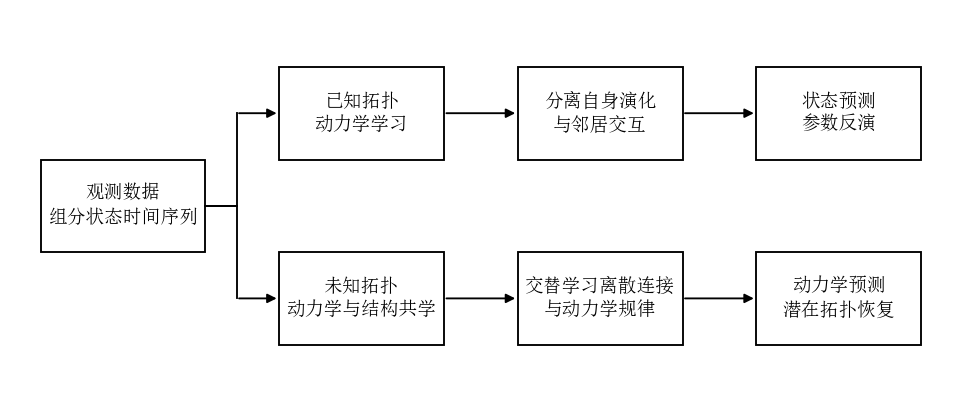

已导出 research_pipeline.pdf 和 research_pipeline.png


In [4]:
research_pipeline()

## 图 2
运行下方单元保存 PDF 矢量图与 PNG 预览。

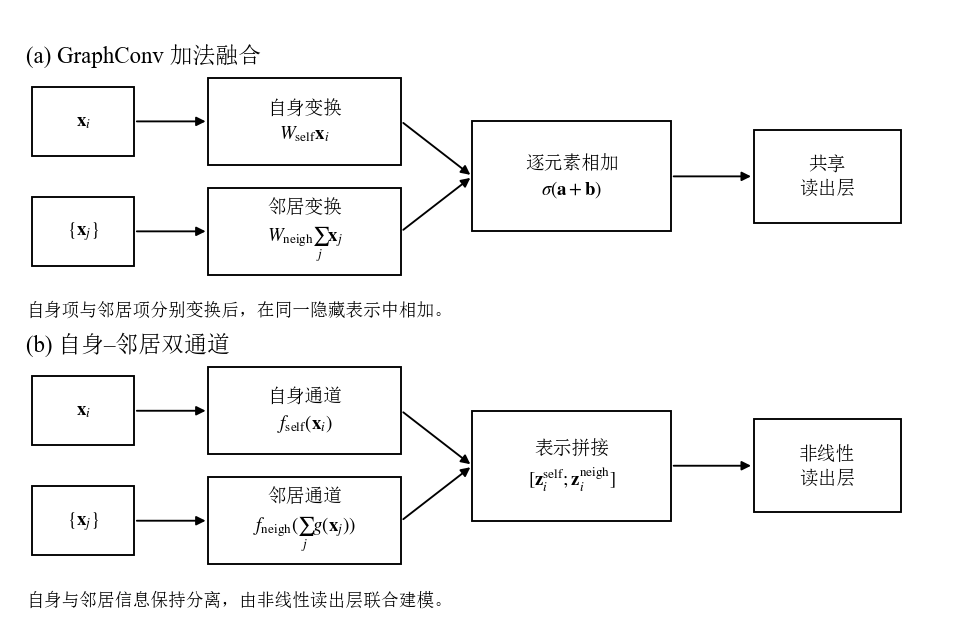

已导出 architecture_compare.pdf 和 architecture_compare.png


In [5]:
architecture_compare()

## 图 3
运行下方单元保存 PDF 矢量图与 PNG 预览。

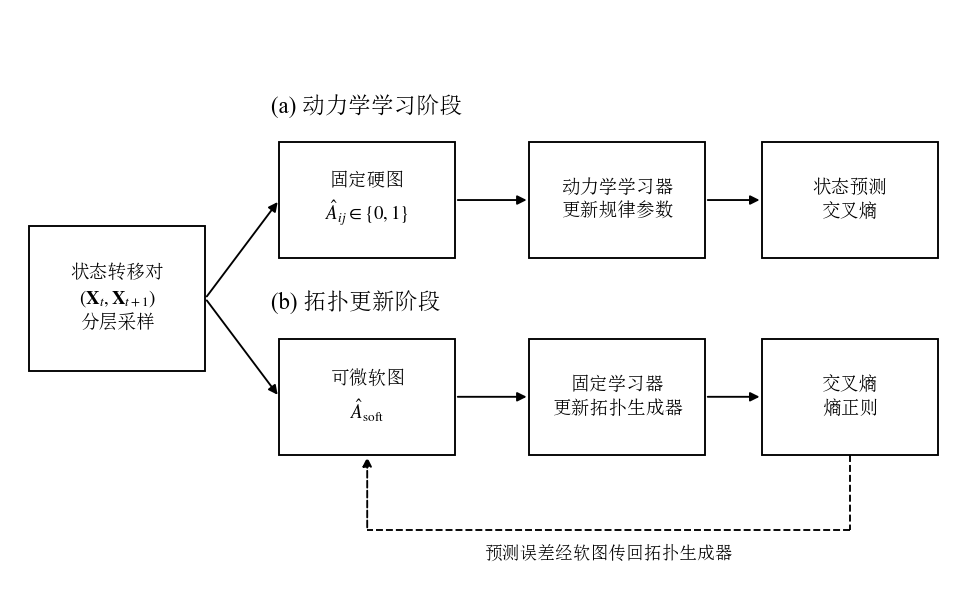

已导出 joint_training_flow.pdf 和 joint_training_flow.png


In [6]:
joint_training_flow()

## 调参示例
将 `ARCH_CHANNEL_GAP` 从 19 改为 22，可以增加上下通道间距。先运行参数区，再运行图 2 单元；若只调文字，则修改 `FONT_SCALE`。保留白底、黑线和无填充设置，避免重新引入彩色底块。